First 5 rows:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  

Dataset shape:
(20640, 8)

Feature names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

Target values:
0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: HousePrice, dtype: float64

Complete dataset:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6

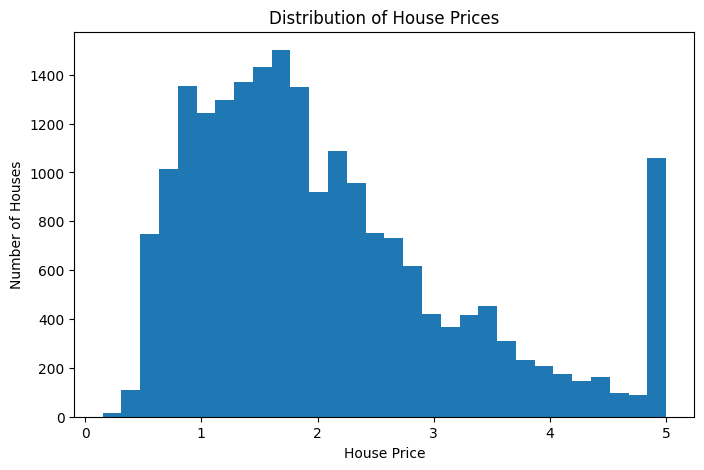


Training samples: 16512
Testing samples: 4128

Features normalized successfully.

Linear Regression model trained successfully.

First 10 predictions:
[0.71912284 1.76401657 2.70965883 2.83892593 2.60465725 2.01175367
 2.64550005 2.16875532 2.74074644 3.91561473]

Model Evaluation:
Mean Squared Error (MSE): 0.5558915986952444
Mean Absolute Error (MAE): 0.5332001304956565
R² Score: 0.5757877060324508

Actual vs Predicted:
   Actual Price  Predicted Price
0       0.47700         0.719123
1       0.45800         1.764017
2       5.00001         2.709659
3       2.18600         2.838926
4       2.78000         2.604657
5       1.58700         2.011754
6       1.98200         2.645500
7       1.57500         2.168755
8       3.40000         2.740746
9       4.46600         3.915615


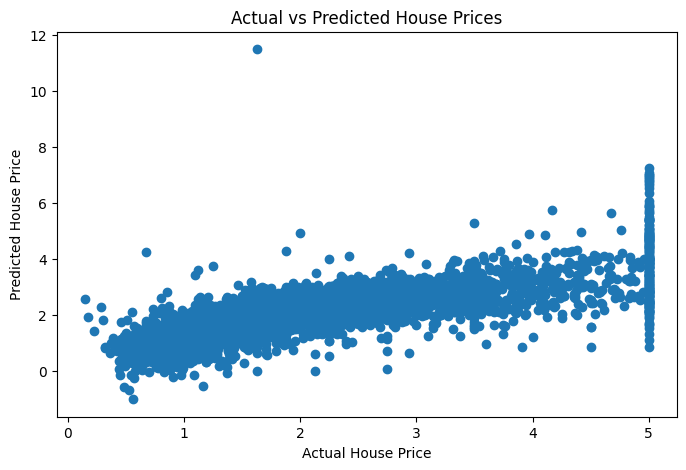

In [1]:
# 1. Import libraries

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)


# 2. Load the dataset

housing = fetch_california_housing()

X = pd.DataFrame(
    housing.data,
    columns=housing.feature_names
)

y = pd.Series(
    housing.target,
    name="HousePrice"
)

print("First 5 rows:")
print(X.head())

print("\nDataset shape:")
print(X.shape)

print("\nFeature names:")
print(X.columns.tolist())

print("\nTarget values:")
print(y.head())


# 3. Combine features and target for exploration

df = X.copy()
df["HousePrice"] = y

print("\nComplete dataset:")
print(df.head())


# 4. Check for missing values

print("\nMissing values:")
print(df.isnull().sum())


# 5. Explore data statistics

print("\nStatistical summary:")
print(df.describe())


# 6. Visualize the target distribution

plt.figure(figsize=(8, 5))

plt.hist(df["HousePrice"], bins=30)

plt.xlabel("House Price")
plt.ylabel("Number of Houses")
plt.title("Distribution of House Prices")

plt.show()


# 7. Separate features and target

X = df.drop("HousePrice", axis=1)
y = df["HousePrice"]


# 8. Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


# 9. Normalize the features

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nFeatures normalized successfully.")


# 10. Train Linear Regression model

model = LinearRegression()

model.fit(X_train_scaled, y_train)

print("\nLinear Regression model trained successfully.")


# 11. Make predictions

y_pred = model.predict(X_test_scaled)

print("\nFirst 10 predictions:")
print(y_pred[:10])


# 12. Evaluate the model

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nModel Evaluation:")
print("Mean Squared Error (MSE):", mse)
print("Mean Absolute Error (MAE):", mae)
print("R² Score:", r2)


# 13. Compare actual and predicted prices

comparison = pd.DataFrame({
    "Actual Price": y_test.values[:10],
    "Predicted Price": y_pred[:10]
})

print("\nActual vs Predicted:")
print(comparison)


# 14. Visualize actual vs predicted prices

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted House Prices")

plt.show()